In [2]:
import pandas as pd
import seaborn as sns
import matplotlib
matplotlib.use("Agg") 
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import sqlite3
from threading import Thread

cnx = sqlite3.connect('../data.db')
cnx_tail = sqlite3.connect('../data/tail-data_1w.db')
try:
    cnx.execute('''
            CREATE INDEX IF NOT EXISTS idx_elasticity_lookup 
            ON data (experiment, provider, date_time, language, cpu, memory, timestamp)
    ''')
    cnx.commit()
    print("Index created/verified")
except Exception as e:
    print(f"Index creation note: {e}")

Index created/verified


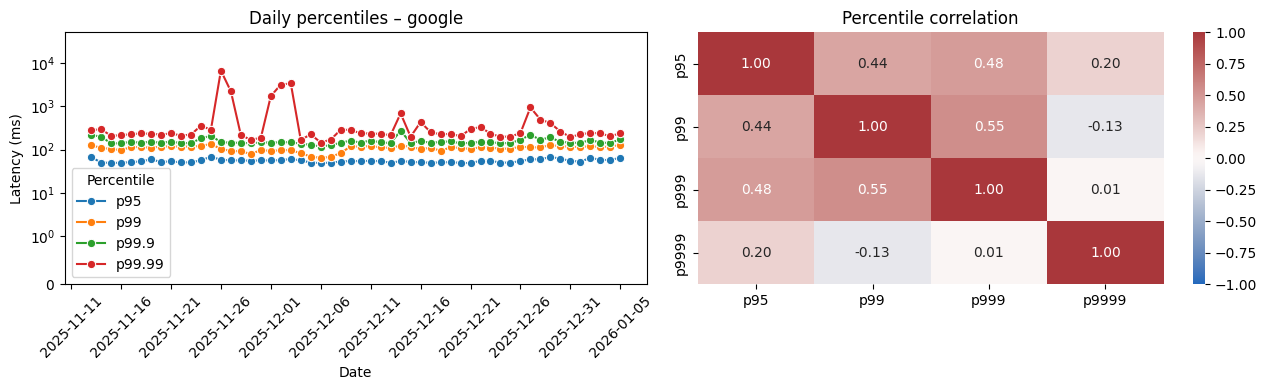

Stability metrics – google (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,54.062979,0.865900,1823392
1,p99,112.229663,2.030112,76774
2,p999,145.575255,3.647873,17274
3,p9999,235.278334,2268.779359,1728


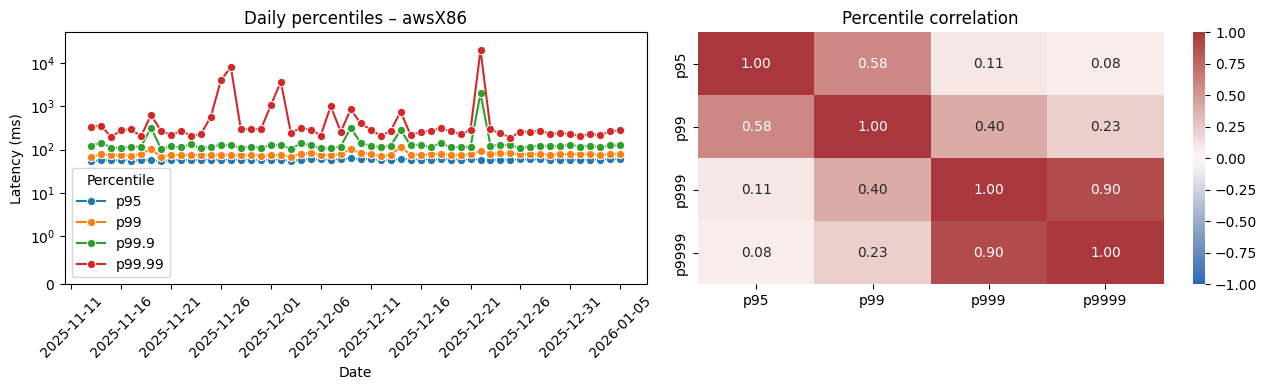

Stability metrics – awsX86 (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,58.291532,0.082965,1537806
1,p99,76.668077,1.158875,64750
2,p999,120.898720,469.939590,14569
3,p9999,272.162190,12209.782843,1457


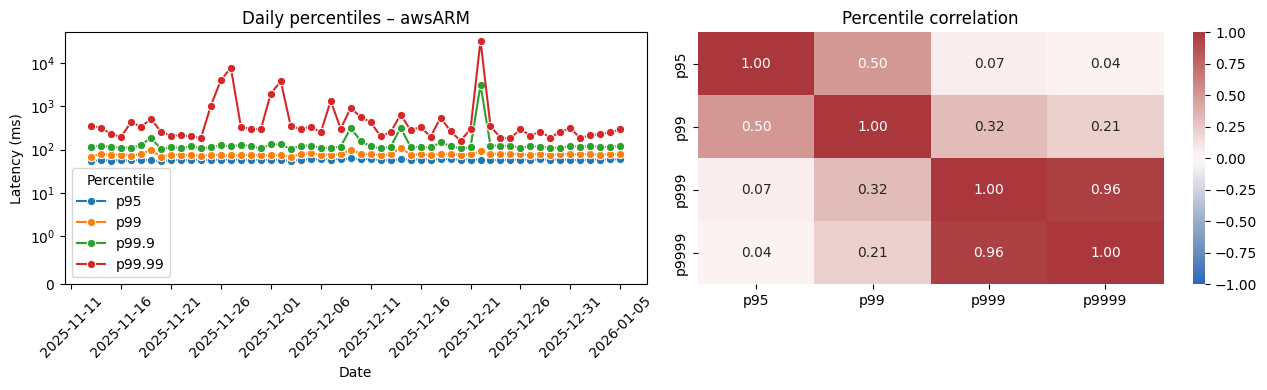

Stability metrics – awsARM (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,58.096384,0.076437,1819729
1,p99,76.831812,0.901718,76620
2,p999,117.382790,1251.242487,17240
3,p9999,295.721777,24854.424730,1724


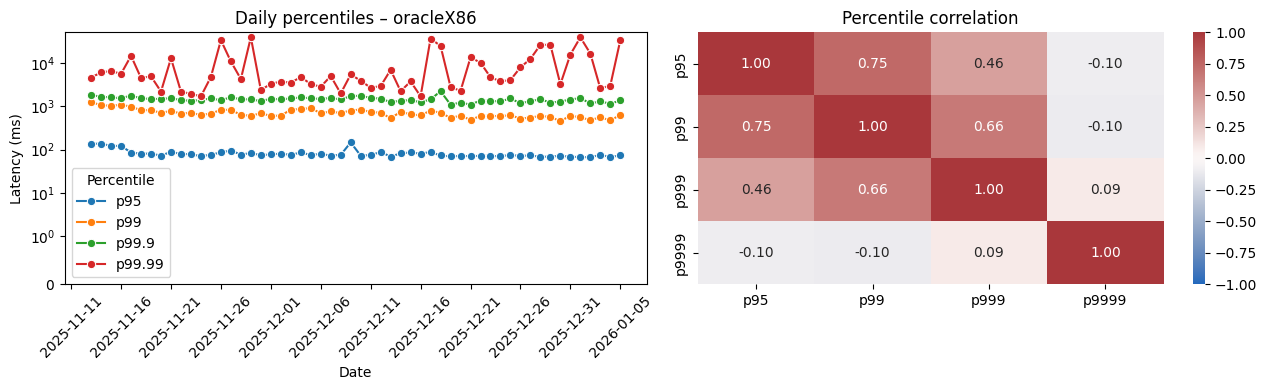

Stability metrics – oracleX86 (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,75.299419,6.164694,1755871
1,p99,677.535425,6.096163,73932
2,p999,1448.916039,1.859481,16634
3,p9999,4667.976023,619.697552,1664


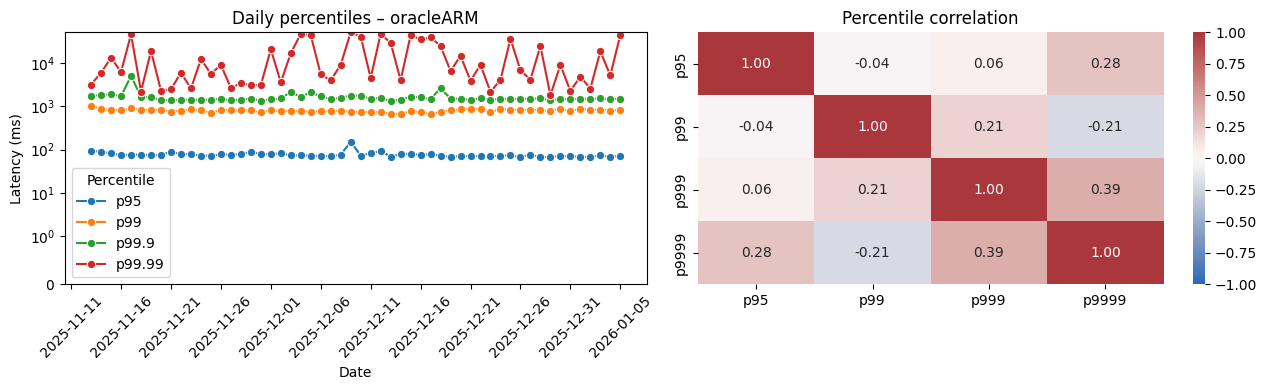

Stability metrics – oracleARM (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,73.591856,2.904680,1791753
1,p99,802.754883,0.638446,75442
2,p999,1498.799718,12.975092,16974
3,p9999,6388.242639,795.572121,1698


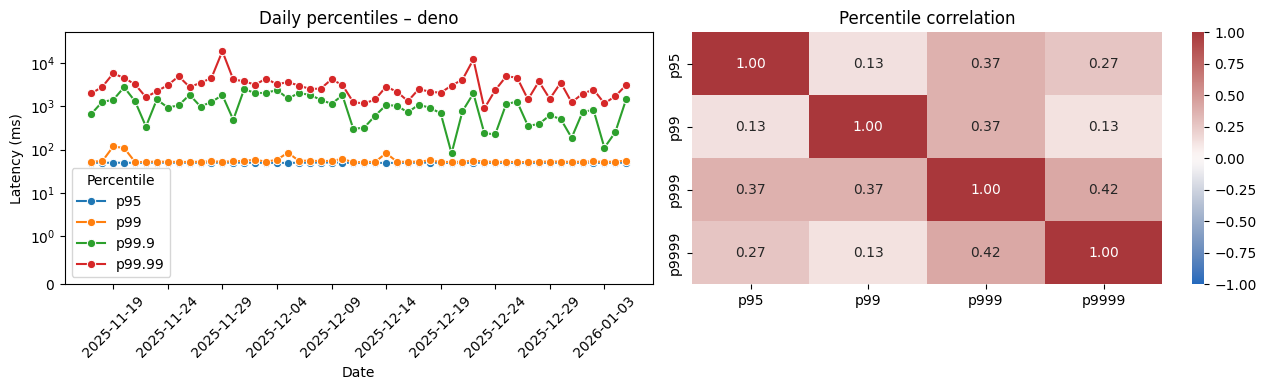

Stability metrics – deno (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,49.295184,0.004042,278524
1,p99,52.622766,6.920048,11728
2,p999,1043.426727,41.895814,2638
3,p9999,2937.038197,94.207804,264


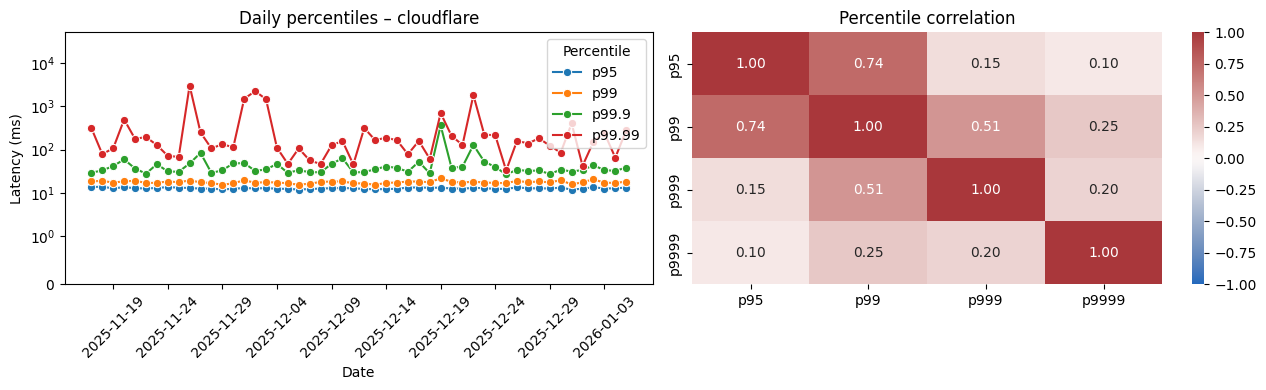

Stability metrics – cloudflare (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,12.673212,0.125986,264557
1,p99,17.500654,0.500065,11140
2,p999,34.313340,206.318308,2506
3,p9999,155.120270,1621.039340,251


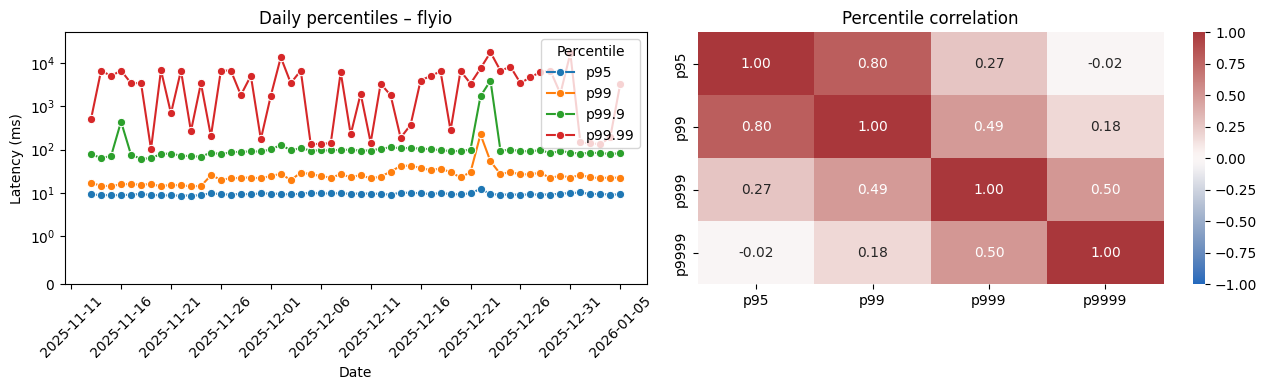

Stability metrics – flyio (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,9.372698,0.349939,1779848
1,p99,22.932837,153.335672,74941
2,p999,92.439380,3790.593568,16862
3,p9999,3425.104262,137.107650,1686


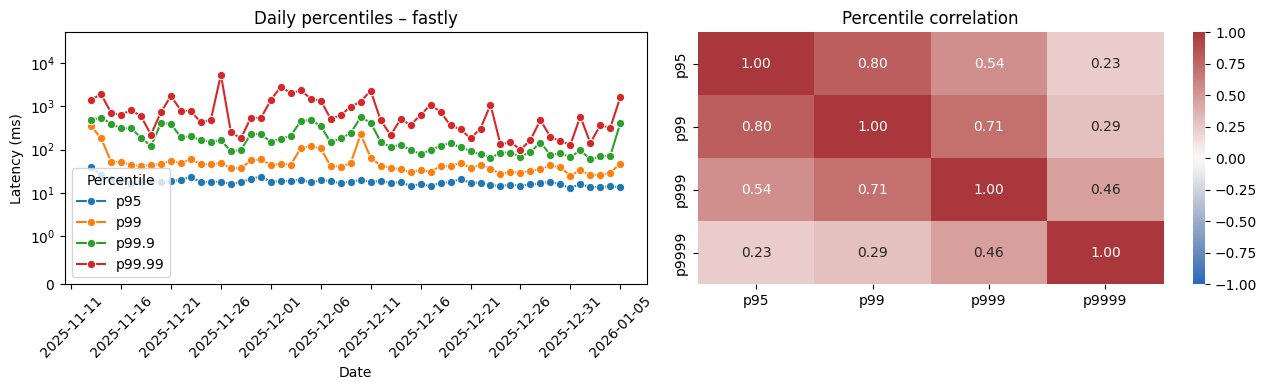

Stability metrics – fastly (warmstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,17.506109,5.075483,608148
1,p99,43.091831,164.942810,25606
2,p999,148.673863,100.716940,5761
3,p9999,561.387904,284.716626,576


In [7]:
# WARM Stability

# Daily percentiles and percentile correlation (warmstart)
import matplotlib.dates as mdates

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

# Lineplot y-axis configuration
lineplot_y_log = True
lineplot_y_log_base = 10
lineplot_y_include_zero = True
lineplot_y_linthresh = 1.0
lineplot_y_min = None
lineplot_y_max = None

# First pass: load data and compute daily percentiles per provider
provider_daily_stats = {}
provider_raw_series = {}
all_percentile_values = []

for provider in providers:
    if provider == "fastly":
        df_provider = pd.read_sql_query(
            """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
            """,
            cnx,
            params=[provider],
        )
    else:
        df_provider = pd.read_sql_query(
            """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
            """,
            cnx,
            params=[provider],
        )
    if df_provider.empty:
        continue

    df_provider["date_time"] = df_provider["date_time"].str[:10]

    daily_stats = (
        df_provider.groupby("date_time", as_index=False)["http_req_waiting"]
        .agg(
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
        )
    )
    daily_stats["date"] = pd.to_datetime(daily_stats["date_time"], errors="coerce")
    daily_stats = daily_stats.dropna(subset=["date"])
    if daily_stats.empty:
        continue

    provider_daily_stats[provider] = daily_stats
    provider_raw_series[provider] = df_provider["http_req_waiting"].dropna()
    all_percentile_values.append(daily_stats[["p95", "p99", "p999", "p9999"]].to_numpy().ravel())

if not provider_daily_stats:
    print("No warmstart data available.")
else:
    all_percentile_values = np.concatenate(all_percentile_values)
    all_percentile_values = all_percentile_values[~np.isnan(all_percentile_values)]

    global_y_min_data = float(np.min(all_percentile_values)) if all_percentile_values.size else 0.0
    global_y_max_data = float(np.max(all_percentile_values)) if all_percentile_values.size else 1.0

    y_bottom = lineplot_y_min
    if y_bottom is None:
        if lineplot_y_include_zero:
            y_bottom = 0.0
        else:
            y_bottom = global_y_min_data
    y_top = lineplot_y_max if lineplot_y_max is not None else global_y_max_data

    if y_top <= y_bottom:
        y_top = y_bottom + 1.0

    corr_cols = ["p95", "p99", "p999", "p9999"]

    # Second pass: plot with shared y-axis limits across all providers
    for provider in providers:
        if provider not in provider_daily_stats:
            continue

        daily_stats = provider_daily_stats[provider]

        fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

        sns.lineplot(data=daily_stats, x="date", y="p95", ax=ax_p, marker="o", label="p95")
        sns.lineplot(data=daily_stats, x="date", y="p99", ax=ax_p, marker="o", label="p99")
        sns.lineplot(data=daily_stats, x="date", y="p999", ax=ax_p, marker="o", label="p99.9")
        sns.lineplot(data=daily_stats, x="date", y="p9999", ax=ax_p, marker="o", label="p99.99")

        ax_p.set_title(f"Daily percentiles – {provider}")
        ax_p.set_xlabel("Date")
        ax_p.set_ylabel("Latency (ms)")

        if lineplot_y_log:
            if lineplot_y_include_zero:
                ax_p.set_yscale("symlog", base=lineplot_y_log_base, linthresh=lineplot_y_linthresh)
            else:
                ax_p.set_yscale("log", base=lineplot_y_log_base)

        ax_p.set_ylim(bottom=y_bottom, top=y_top)

        ax_p.xaxis.set_major_locator(mdates.DayLocator(interval=5))
        ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
        ax_p.tick_params(axis="x", rotation=45)
        ax_p.legend(title="Percentile")

        corr = daily_stats[corr_cols].corr()
        sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
        ax_corr.set_title("Percentile correlation")

        plt.tight_layout()
        plt.show()

        # Non-cumulative number of raw datapoints per percentile band.
        raw_s = provider_raw_series[provider]
        percentile_levels = {"p95": 0.95, "p99": 0.99, "p999": 0.999, "p9999": 0.9999}
        percentile_thresholds = (
            {k: float(raw_s.quantile(q)) for k, q in percentile_levels.items()} if not raw_s.empty else {}
        )
        prev_cum = 0

        stability_rows = []
        for col in corr_cols:
            series = daily_stats[col].dropna()
            if series.empty:
                variance = np.nan
                median = np.nan
                rel_variance_pct = np.nan
            else:
                median = float(series.median())
                variance = float(((series - median) ** 2).mean())
                rel_variance_pct = (variance / (median ** 2)) * 100 if median else np.nan

            if raw_s.empty:
                cum = 0
            else:
                threshold = percentile_thresholds[col]
                cum = int((raw_s <= threshold).sum())
            n_points = cum - prev_cum
            prev_cum = cum

            stability_rows.append(
                {
                    "percentile": col,
                    "median_ms": median,
                    "variance_pct_of_median": rel_variance_pct,
                    "n_points": n_points,
                }
            )

        stability_df = pd.DataFrame(stability_rows)
        print(f"Stability metrics – {provider} (warmstart)")
        display(stability_df)

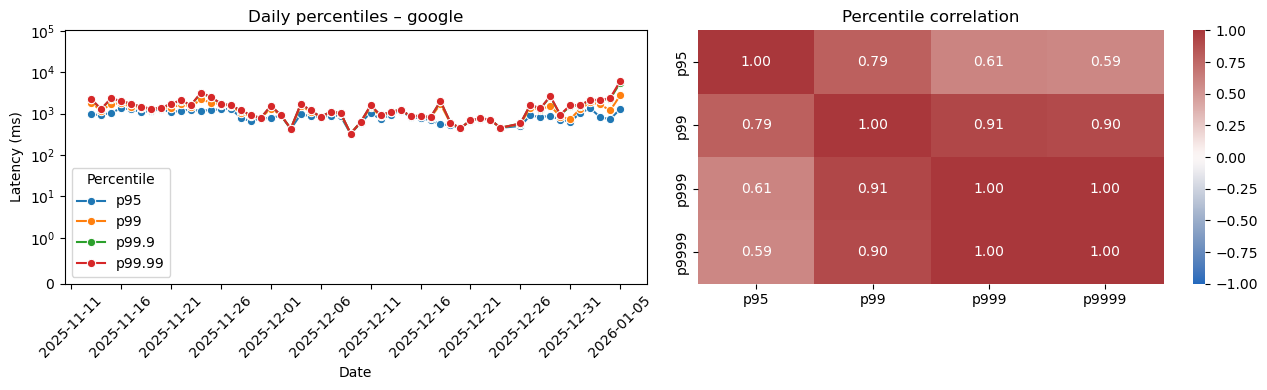

Stability metrics – google (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,867.819825,9.466432,2304
1,p99,1193.378178,16.880419,97
2,p999,1311.122922,42.529530,22
3,p9999,1316.704757,48.758894,2


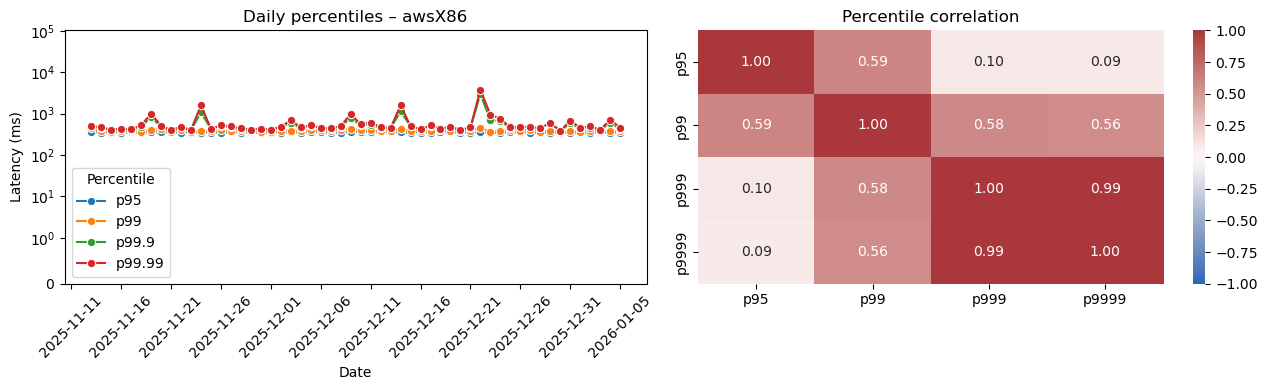

Stability metrics – awsX86 (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,348.812461,0.027213,24196
1,p99,379.630451,0.313197,1019
2,p999,457.476213,68.928463,229
3,p9999,474.380362,120.590677,23


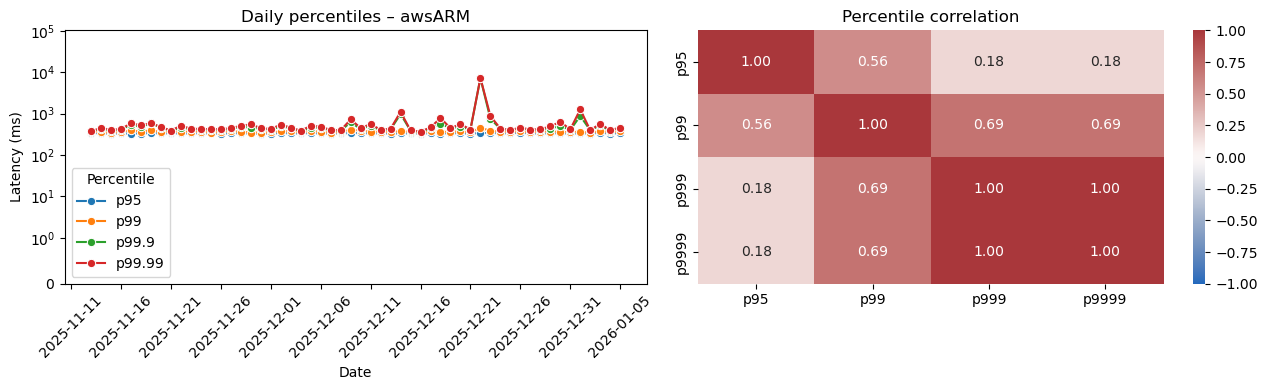

Stability metrics – awsARM (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,333.978230,0.012993,26969
1,p99,364.459012,0.242197,1136
2,p999,432.041712,465.236945,255
3,p9999,449.298301,441.642014,26


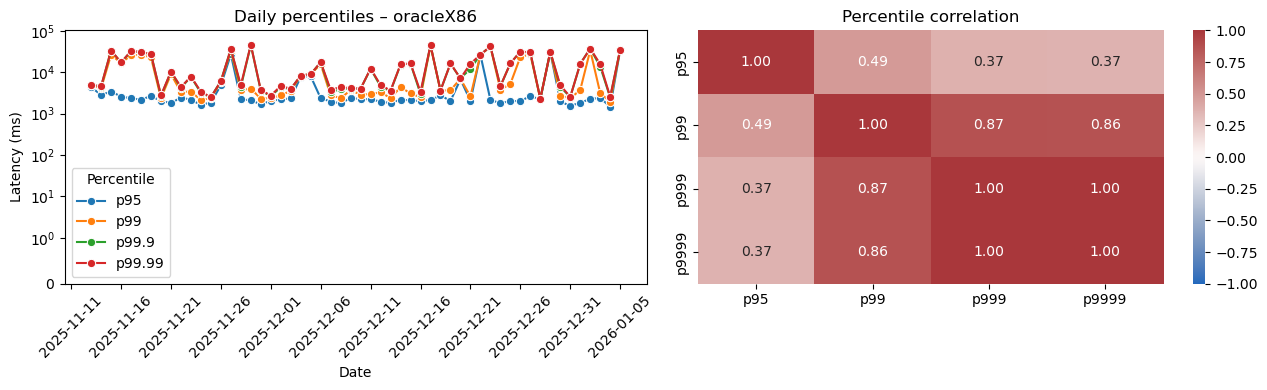

Stability metrics – oracleX86 (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,2195.088408,1220.668949,17163
1,p99,3713.212305,1387.644354,723
2,p999,8049.969550,325.693546,162
3,p9999,8081.367525,327.460474,17


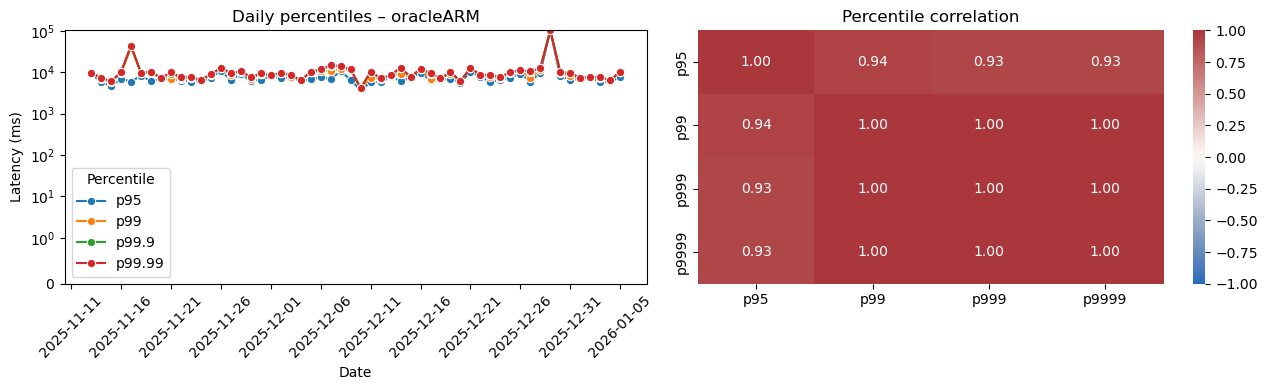

Stability metrics – oracleARM (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,6842.170453,355.204346,6958
1,p99,8332.409116,270.487778,293
2,p999,9378.738193,215.128592,66
3,p9999,9558.482780,206.686975,7


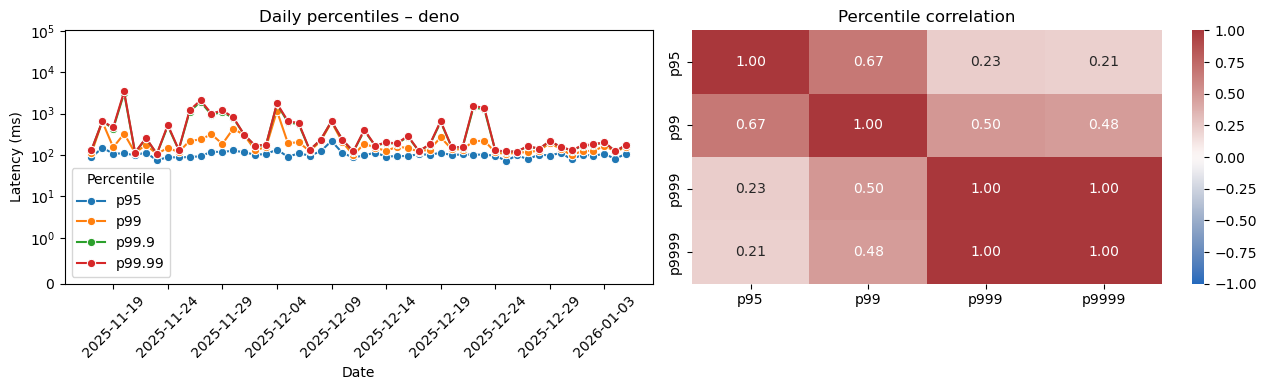

Stability metrics – deno (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,101.752602,4.737246,4524
1,p99,152.188570,147.935937,191
2,p999,191.336946,1122.734583,43
3,p9999,196.262827,1252.458517,4


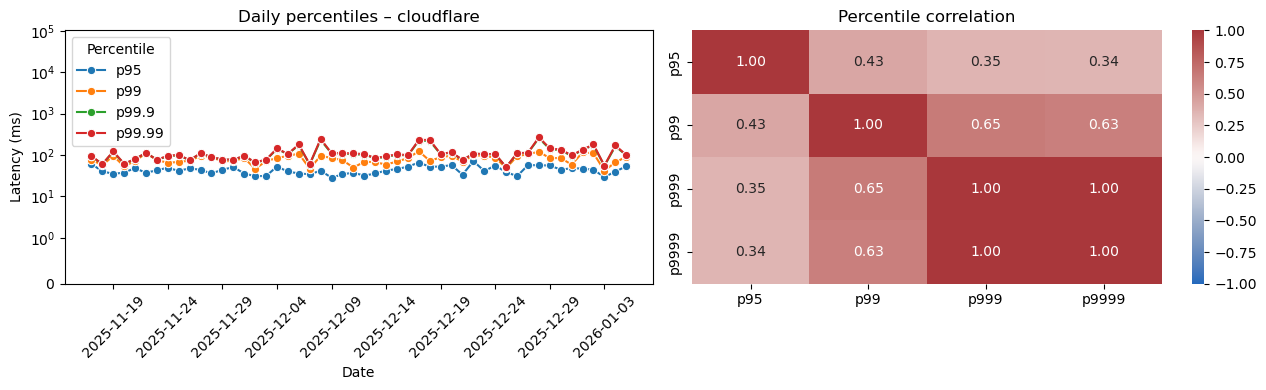

Stability metrics – cloudflare (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,42.474426,5.411953,4440
1,p99,80.459350,6.086987,187
2,p999,102.769699,19.574780,42
3,p9999,105.419179,21.338282,4


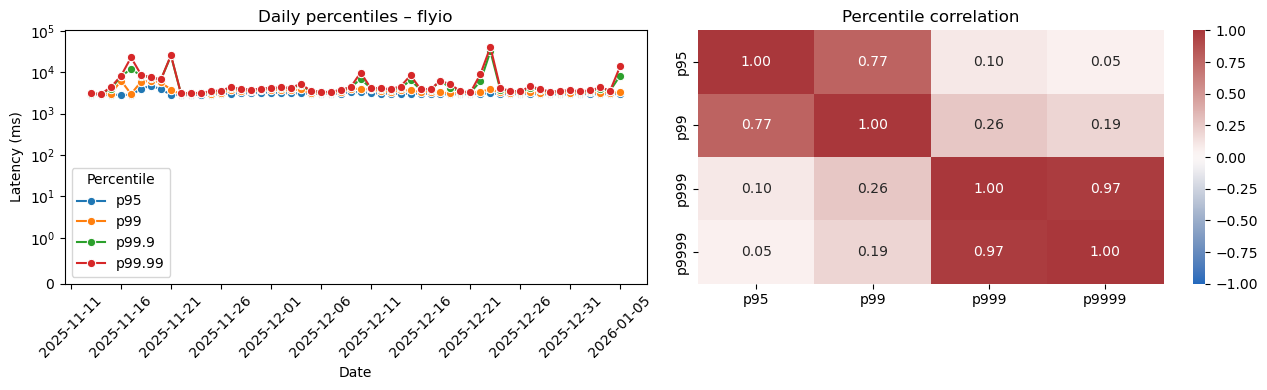

Stability metrics – flyio (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,2978.347181,1.180984,27650
1,p99,3251.175833,6.189859,1164
2,p999,3876.235586,175.190561,262
3,p9999,3985.112985,283.137166,27


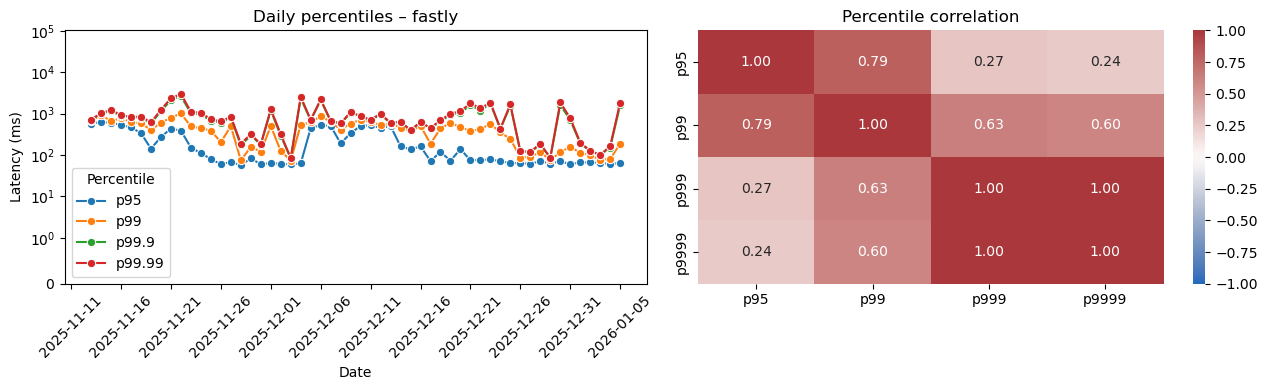

Stability metrics – fastly (coldstart)


,percentile,median_ms,variance_pct_of_median,n_points
0,p95,81.399910,778.640979,9661
1,p99,439.386348,32.601341,407
2,p999,697.910318,78.769752,91
3,p9999,722.877151,91.991035,9


In [ ]:
# COLD Stability

# Daily percentiles and percentile correlation (coldstart)
import matplotlib.dates as mdates

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

# Lineplot y-axis configuration
lineplot_y_log = True
lineplot_y_log_base = 10
lineplot_y_include_zero = True
lineplot_y_linthresh = 1.0
lineplot_y_min = None
lineplot_y_max = None

# First pass: load data and compute daily percentiles per provider
provider_daily_stats = {}
provider_raw_series = {}
all_percentile_values = []

for provider in providers:
    df_provider = pd.read_sql_query(
        """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
        """,
        cnx,
        params=[provider],
    )
    if df_provider.empty:
        continue

    df_provider["date_time"] = df_provider["date_time"].str[:10]

    daily_stats = (
        df_provider.groupby("date_time", as_index=False)["http_req_waiting"]
        .agg(
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
        )
    )
    daily_stats["date"] = pd.to_datetime(daily_stats["date_time"], errors="coerce")
    daily_stats = daily_stats.dropna(subset=["date"])
    if daily_stats.empty:
        continue

    provider_daily_stats[provider] = daily_stats
    provider_raw_series[provider] = df_provider["http_req_waiting"].dropna()
    all_percentile_values.append(daily_stats[["p95", "p99", "p999", "p9999"]].to_numpy().ravel())

if not provider_daily_stats:
    print("No coldstart data available.")
else:
    all_percentile_values = np.concatenate(all_percentile_values)
    all_percentile_values = all_percentile_values[~np.isnan(all_percentile_values)]

    global_y_min_data = float(np.min(all_percentile_values)) if all_percentile_values.size else 0.0
    global_y_max_data = float(np.max(all_percentile_values)) if all_percentile_values.size else 1.0

    y_bottom = lineplot_y_min
    if y_bottom is None:
        if lineplot_y_include_zero:
            y_bottom = 0.0
        else:
            y_bottom = global_y_min_data
    y_top = lineplot_y_max if lineplot_y_max is not None else global_y_max_data

    if y_top <= y_bottom:
        y_top = y_bottom + 1.0

    corr_cols = ["p95", "p99", "p999", "p9999"]

    # Second pass: plot with shared y-axis limits across all providers
    for provider in providers:
        if provider not in provider_daily_stats:
            continue

        daily_stats = provider_daily_stats[provider]

        fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

        sns.lineplot(data=daily_stats, x="date", y="p95", ax=ax_p, marker="o", label="p95")
        sns.lineplot(data=daily_stats, x="date", y="p99", ax=ax_p, marker="o", label="p99")
        sns.lineplot(data=daily_stats, x="date", y="p999", ax=ax_p, marker="o", label="p99.9")
        sns.lineplot(data=daily_stats, x="date", y="p9999", ax=ax_p, marker="o", label="p99.99")

        ax_p.set_title(f"Daily percentiles – {provider}")
        ax_p.set_xlabel("Date")
        ax_p.set_ylabel("Latency (ms)")

        if lineplot_y_log:
            if lineplot_y_include_zero:
                ax_p.set_yscale("symlog", base=lineplot_y_log_base, linthresh=lineplot_y_linthresh)
            else:
                ax_p.set_yscale("log", base=lineplot_y_log_base)

        ax_p.set_ylim(bottom=y_bottom, top=y_top)

        ax_p.xaxis.set_major_locator(mdates.DayLocator(interval=5))
        ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
        ax_p.tick_params(axis="x", rotation=45)
        ax_p.legend(title="Percentile")

        corr = daily_stats[corr_cols].corr()
        sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
        ax_corr.set_title("Percentile correlation")

        plt.tight_layout()
        plt.show()

        # Non-cumulative number of raw datapoints per percentile band.
        raw_s = provider_raw_series[provider]
        percentile_levels = {"p95": 0.95, "p99": 0.99, "p999": 0.999, "p9999": 0.9999}
        percentile_thresholds = (
            {k: float(raw_s.quantile(q)) for k, q in percentile_levels.items()} if not raw_s.empty else {}
        )
        prev_cum = 0

        stability_rows = []
        for col in corr_cols:
            series = daily_stats[col].dropna()
            if series.empty:
                variance = np.nan
                median = np.nan
                rel_variance_pct = np.nan
            else:
                median = float(series.median())
                variance = float(((series - median) ** 2).mean())
                rel_variance_pct = (variance / (median ** 2)) * 100 if median else np.nan

            if raw_s.empty:
                cum = 0
            else:
                threshold = percentile_thresholds[col]
                cum = int((raw_s <= threshold).sum())
            n_points = cum - prev_cum
            prev_cum = cum

            stability_rows.append(
                {
                    "percentile": col,
                    "median_ms": median,
                    "variance_pct_of_median": rel_variance_pct,
                    "n_points": n_points,
                }
            )

        stability_df = pd.DataFrame(stability_rows)
        print(f"Stability metrics – {provider} (coldstart)")
        display(stability_df)

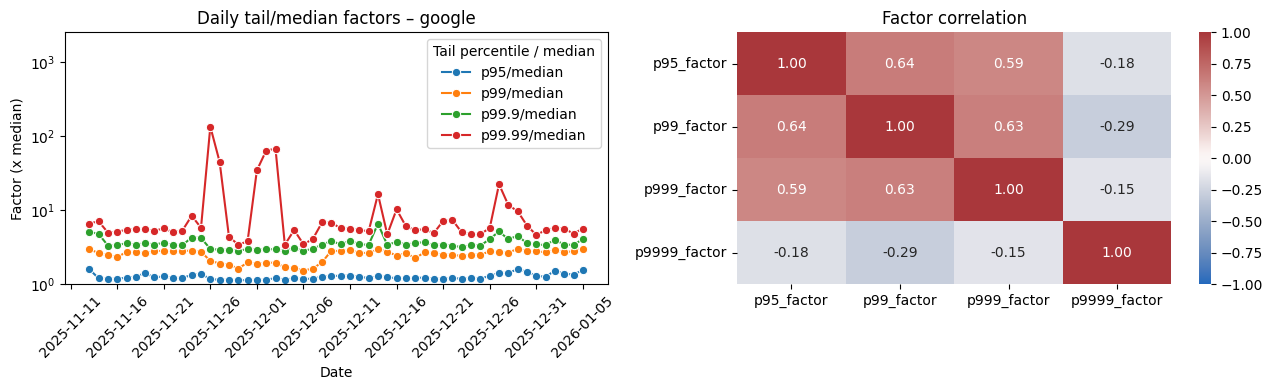

Stability metrics (tail/median factor) – google (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.215889,1.062283,1823392
1,p99,2.645662,2.838684,76774
2,p999,3.410206,4.075239,17274
3,p9999,5.589888,1601.978707,1728


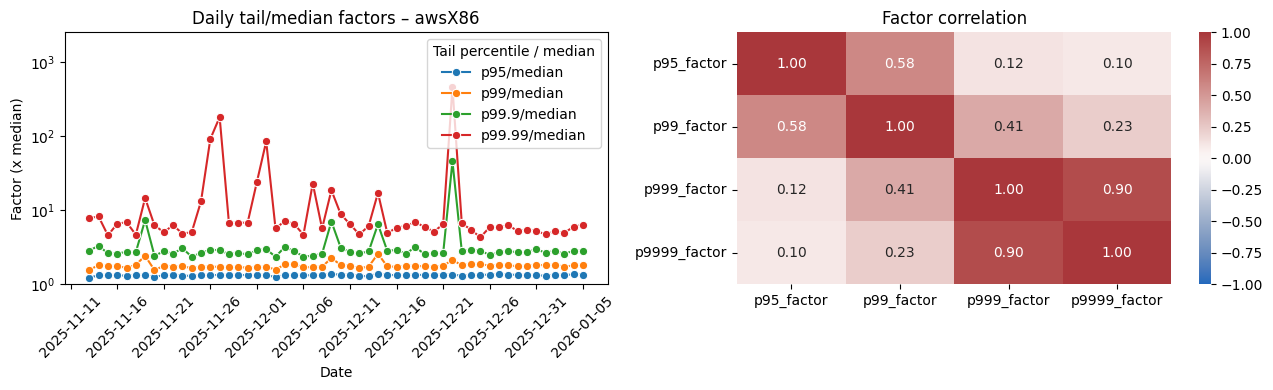

Stability metrics (tail/median factor) – awsX86 (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.325190,0.045885,1537806
1,p99,1.746898,1.070237,64750
2,p999,2.741534,469.970175,14569
3,p9999,6.265759,11847.975495,1457


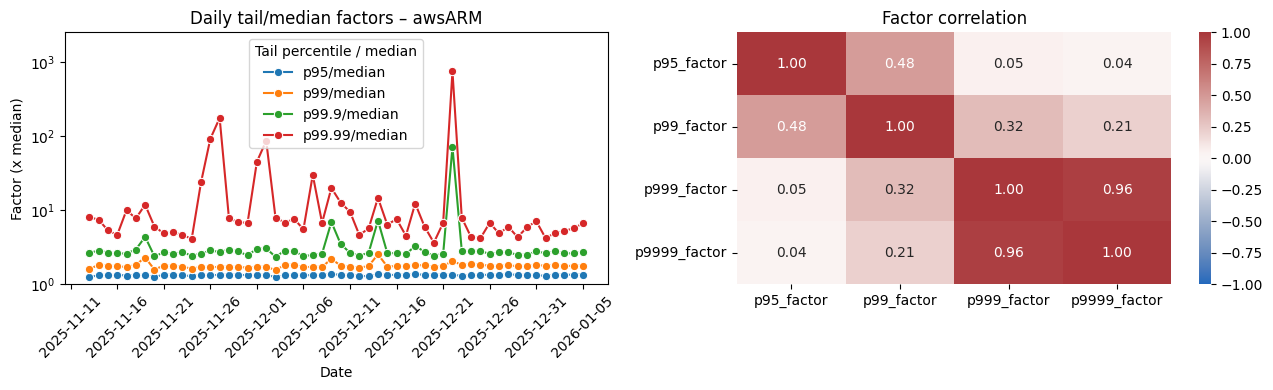

Stability metrics (tail/median factor) – awsARM (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.325765,0.039711,1819729
1,p99,1.751544,0.844810,76620
2,p999,2.670291,1247.027257,17240
3,p9999,6.739635,24720.131859,1724


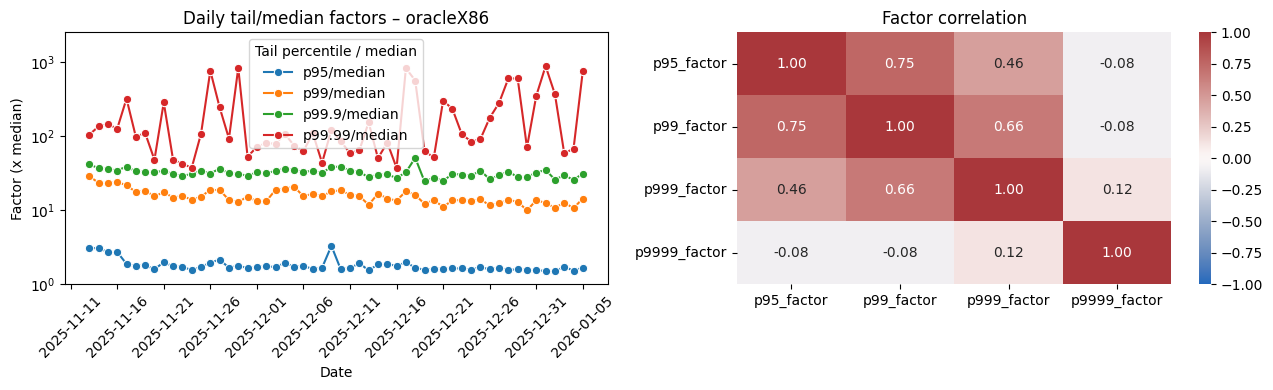

Stability metrics (tail/median factor) – oracleX86 (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.685133,6.205658,1755871
1,p99,15.058548,6.313641,73932
2,p999,32.135104,1.952778,16634
3,p9999,106.097103,603.393427,1664


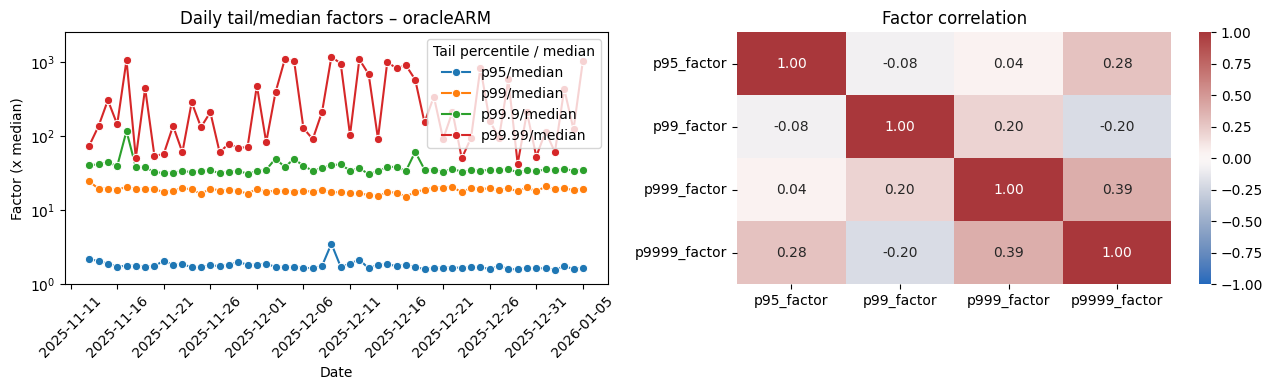

Stability metrics (tail/median factor) – oracleARM (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.716261,2.736666,1791753
1,p99,18.652633,0.667894,75442
2,p999,34.912095,12.890466,16974
3,p9999,149.562480,788.920840,1698


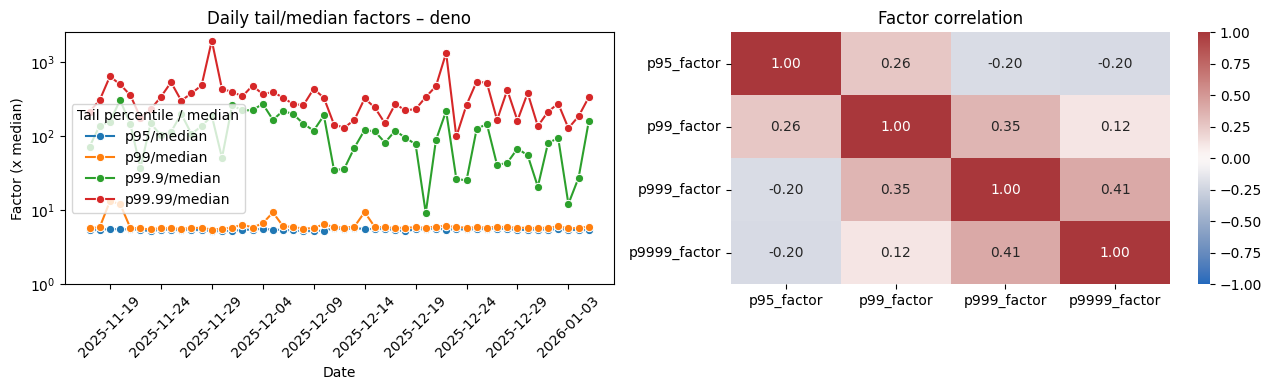

Stability metrics (tail/median factor) – deno (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,5.429806,0.056280,278524
1,p99,5.822759,7.216663,11728
2,p999,115.666168,40.561162,2638
3,p9999,328.484368,84.568551,264


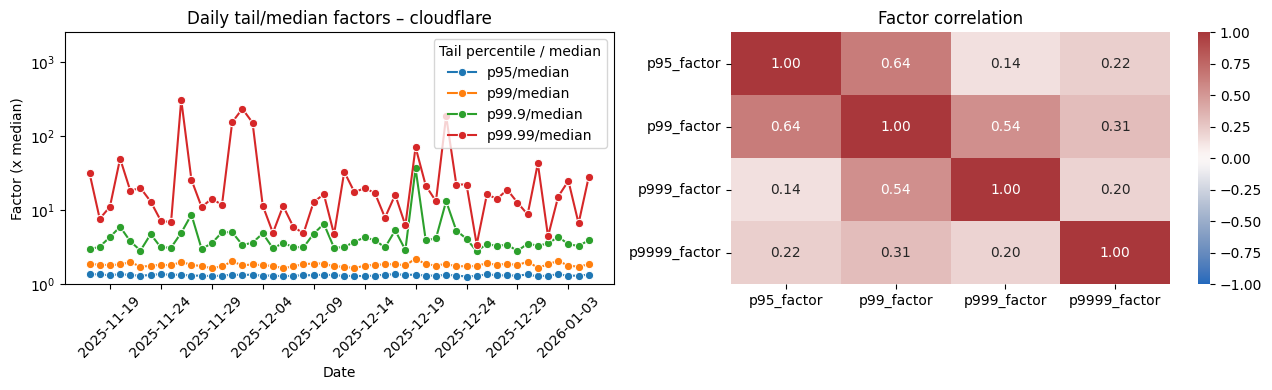

Stability metrics (tail/median factor) – cloudflare (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.312474,0.040673,264557
1,p99,1.804441,0.379978,11140
2,p999,3.575717,196.902219,2506
3,p9999,15.730703,1707.319833,251


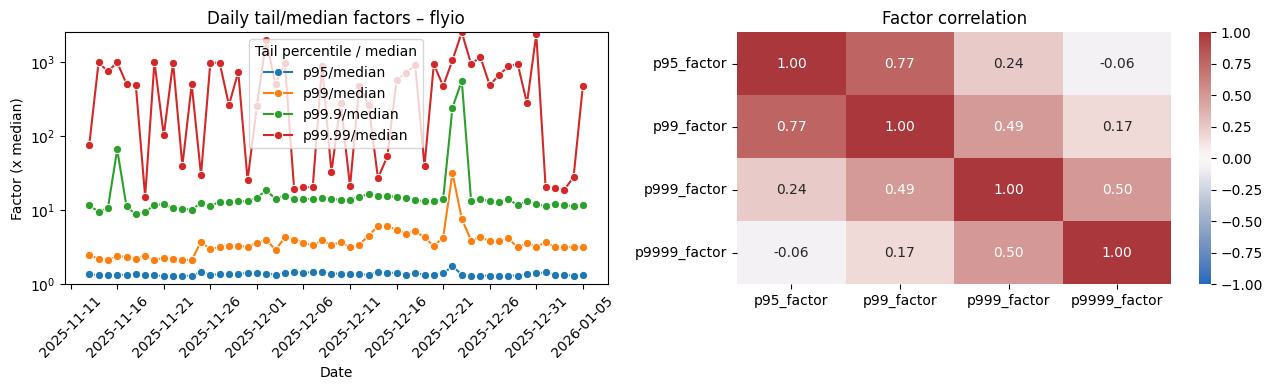

Stability metrics (tail/median factor) – flyio (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.347799,0.312723,1779848
1,p99,3.358864,144.002144,74941
2,p999,13.239207,3797.872495,16862
3,p9999,492.987706,138.284985,1686


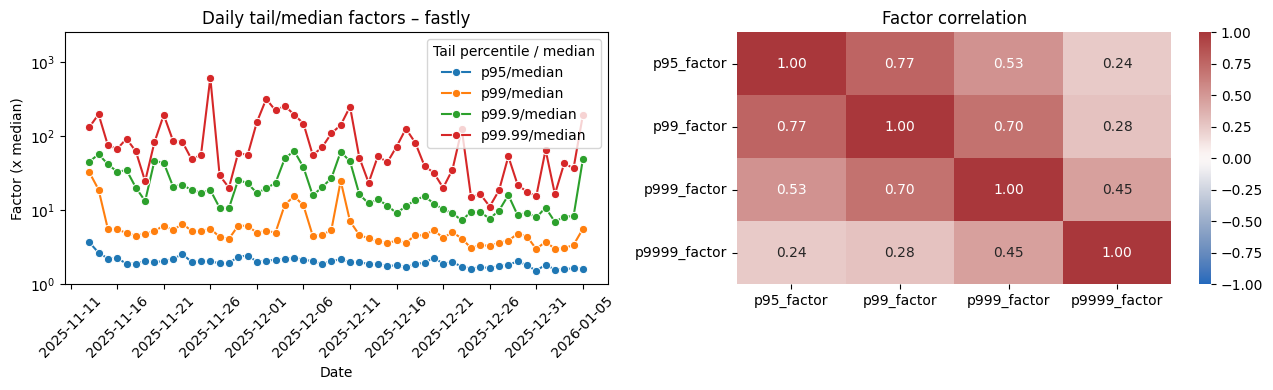

Stability metrics (tail/median factor) – fastly (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.974088,2.897978,608148
1,p99,4.809463,131.333745,25606
2,p999,16.191103,104.486718,5761
3,p9999,61.465787,303.771420,576


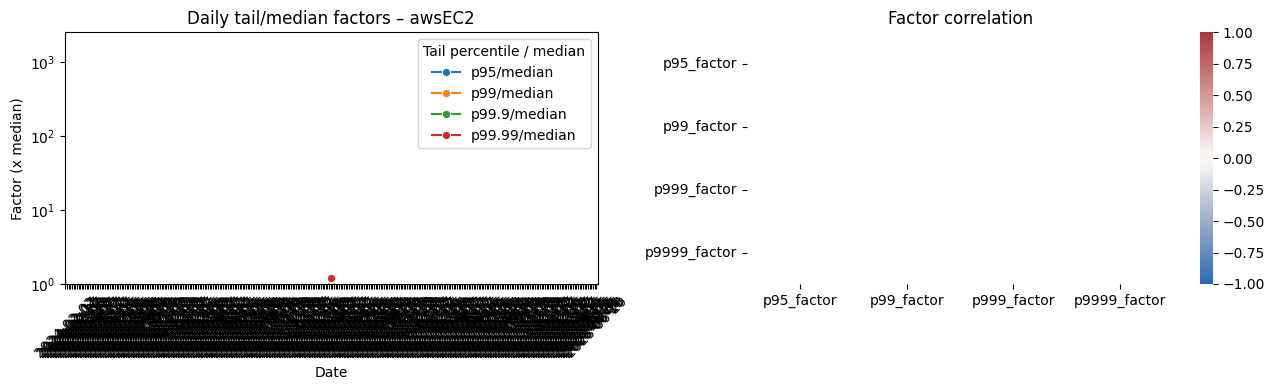

Stability metrics (tail/median factor) – awsEC2 (warmstart)


,percentile,median_factor,variance_pct_of_median_factor,n_points
0,p95,1.014358,0.0,1426
1,p99,1.066289,0.0,60
2,p999,1.166831,0.0,13
3,p9999,1.188797,0.0,1


In [ ]:
# WARM Stability (tail percentiles relative to median)

# Daily percentile/median factors and correlation (warmstart)
import matplotlib.dates as mdates

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

# Lineplot y-axis configuration (factor scale)
lineplot_y_log = True
lineplot_y_log_base = 10
lineplot_y_include_one = True
lineplot_y_linthresh = 0.05
lineplot_y_min = None
lineplot_y_max = None

# First pass: load data and compute daily median + tail percentile factors per provider
provider_daily_stats = {}
provider_raw_series = {}
all_factor_values = []

for provider in providers:
    if provider == "fastly":
        df_provider = pd.read_sql_query(
            """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
            """,
            cnx,
            params=[provider],
        )
    else:
        df_provider = pd.read_sql_query(
            """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
            """,
            cnx,
            params=[provider],
        )
    if df_provider.empty:
        continue

    df_provider["date_time"] = df_provider["date_time"].str[:10]

    daily_stats = (
        df_provider.groupby("date_time", as_index=False)["http_req_waiting"]
        .agg(
            median=lambda s: s.quantile(0.50),
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
        )
    )

    for col in ["p95", "p99", "p999", "p9999"]:
        daily_stats[f"{col}_factor"] = np.where(
            daily_stats["median"] > 0,
            daily_stats[col] / daily_stats["median"],
            np.nan,
        )

    daily_stats["date"] = pd.to_datetime(daily_stats["date_time"], errors="coerce")
    daily_stats = daily_stats.dropna(subset=["date"] + [f"{c}_factor" for c in ["p95", "p99", "p999", "p9999"]])
    if daily_stats.empty:
        continue

    provider_daily_stats[provider] = daily_stats
    provider_raw_series[provider] = df_provider["http_req_waiting"].dropna()
    all_factor_values.append(daily_stats[["p95_factor", "p99_factor", "p999_factor", "p9999_factor"]].to_numpy().ravel())

if not provider_daily_stats:
    print("No warmstart data available.")
else:
    all_factor_values = np.concatenate(all_factor_values)
    all_factor_values = all_factor_values[~np.isnan(all_factor_values)]

    global_y_min_data = float(np.min(all_factor_values)) if all_factor_values.size else 1.0
    global_y_max_data = float(np.max(all_factor_values)) if all_factor_values.size else 1.0

    y_bottom = lineplot_y_min
    if y_bottom is None:
        if lineplot_y_include_one:
            y_bottom = min(1.0, global_y_min_data)
        else:
            y_bottom = global_y_min_data
    y_top = lineplot_y_max if lineplot_y_max is not None else global_y_max_data

    if y_top <= y_bottom:
        y_top = y_bottom + 0.1

    factor_cols = ["p95_factor", "p99_factor", "p999_factor", "p9999_factor"]

    # Second pass: plot with shared y-axis limits across all providers
    for provider in providers:
        if provider not in provider_daily_stats:
            continue

        daily_stats = provider_daily_stats[provider]

        fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

        sns.lineplot(data=daily_stats, x="date", y="p95_factor", ax=ax_p, marker="o", label="p95/median")
        sns.lineplot(data=daily_stats, x="date", y="p99_factor", ax=ax_p, marker="o", label="p99/median")
        sns.lineplot(data=daily_stats, x="date", y="p999_factor", ax=ax_p, marker="o", label="p99.9/median")
        sns.lineplot(data=daily_stats, x="date", y="p9999_factor", ax=ax_p, marker="o", label="p99.99/median")

        ax_p.set_title(f"Daily tail/median factors – {provider}")
        ax_p.set_xlabel("Date")
        ax_p.set_ylabel("Factor (x median)")

        if lineplot_y_log:
            if lineplot_y_include_one:
                ax_p.set_yscale("symlog", base=lineplot_y_log_base, linthresh=lineplot_y_linthresh)
            else:
                ax_p.set_yscale("log", base=lineplot_y_log_base)

        ax_p.set_ylim(bottom=y_bottom, top=y_top)

        ax_p.xaxis.set_major_locator(mdates.DayLocator(interval=5))
        ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
        ax_p.tick_params(axis="x", rotation=45)
        ax_p.legend(title="Tail percentile / median")

        corr = daily_stats[factor_cols].corr()
        sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
        ax_corr.set_title("Factor correlation")

        plt.tight_layout()
        plt.show()

        # Non-cumulative number of raw datapoints per percentile band.
        raw_s = provider_raw_series[provider]
        percentile_levels = {"p95": 0.95, "p99": 0.99, "p999": 0.999, "p9999": 0.9999}
        percentile_thresholds = (
            {k: float(raw_s.quantile(q)) for k, q in percentile_levels.items()} if not raw_s.empty else {}
        )
        prev_cum = 0

        stability_rows = []
        for col in ["p95", "p99", "p999", "p9999"]:
            factor_col = f"{col}_factor"
            series = daily_stats[factor_col].dropna()
            if series.empty:
                variance = np.nan
                median_factor = np.nan
                rel_variance_pct = np.nan
            else:
                median_factor = float(series.median())
                variance = float(((series - median_factor) ** 2).mean())
                rel_variance_pct = (variance / (median_factor ** 2)) * 100 if median_factor else np.nan

            if raw_s.empty:
                cum = 0
            else:
                threshold = percentile_thresholds[col]
                cum = int((raw_s <= threshold).sum())
            n_points = cum - prev_cum
            prev_cum = cum

            stability_rows.append(
                {
                    "percentile": col,
                    "median_factor": median_factor,
                    "variance_pct_of_median_factor": rel_variance_pct,
                    "n_points": n_points,
                }
            )

        stability_df = pd.DataFrame(stability_rows)
        print(f"Stability metrics (tail/median factor) – {provider} (warmstart)")
        display(stability_df)

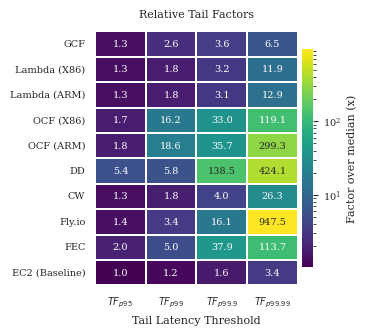

Heatmap table:


,$TF_{p95}$,$TF_{p99}$,$TF_{p99.9}$,$TF_{p99.99}$
provider,,,,
GCF,1.295114,2.588823,3.558100,6.485454
Lambda (X86),1.322306,1.768920,3.174988,11.939605
Lambda (ARM),1.325259,1.765839,3.139157,12.919942
OCF (X86),1.734592,16.235311,32.955625,119.066585
OCF (ARM),1.759582,18.626799,35.711509,299.257606
DD,5.433381,5.847905,138.460022,424.052020
CW,1.321675,1.826514,3.991535,26.330824
Fly.io,1.358242,3.385080,16.134265,947.467280
FEC,1.964155,5.048876,37.866072,113.686417


In [3]:
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
import numpy as np

providers_warm = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
provider_order = providers_warm + ["awsEC2"]

provider_map = {
    "google": "GCF",
    "awsX86": "Lambda (X86)",
    "awsARM": "Lambda (ARM)",
    "oracleX86": "OCF (X86)",
    "oracleARM": "OCF (ARM)",
    "deno": "DD",
    "cloudflare": "CW",
    "flyio": "Fly.io",
    "fastly": "FEC",
    "awsEC2": "EC2 (Baseline)"
}

# Map percentiles to their LaTeX equivalents for the paper
cols = ["$TF_{p95}$", "$TF_{p99}$", "$TF_{p99.9}$", "$TF_{p99.99}$"]

def load_latencies_sqlite_optimized(provider: str) -> np.ndarray:
    """
    Bypasses Pandas and streams data directly from the SQLite cursor into a 
    memory-efficient float32 NumPy array.
    """
    if provider == "awsEC2":
        query = "SELECT http_req_waiting FROM data WHERE provider = ? AND experiment = 'warmstart'"
        cursor = cnx_tail.cursor()
    elif provider == "fastly":
        query = "SELECT http_req_waiting FROM data WHERE provider = ? AND experiment = 'warmstart'"
        cursor = cnx.cursor()
    else:
        query = "SELECT http_req_waiting FROM data WHERE provider = ? AND experiment = 'warmstart' AND cold_starts = 0"
        cursor = cnx.cursor()

    cursor.execute(query, (provider,))
    
    # np.fromiter streams the data row-by-row into memory. 
    # dtype=np.float32 halves the memory usage compared to default float64.
    latencies = np.fromiter((row[0] for row in cursor if row[0] is not None), dtype=np.float32)
    return latencies

rows = []
for provider in provider_order:
    lat = load_latencies_sqlite_optimized(provider)
    mapped_name = provider_map.get(provider, provider)
    
    if lat.size == 0:
        rows.append({"provider": mapped_name, **{col: np.nan for col in cols}})
        continue

    median = float(np.quantile(lat, 0.5))
    if median <= 0:
        rows.append({"provider": mapped_name, **{col: np.nan for col in cols}})
        continue

    rows.append({
        "provider": mapped_name,
        "$TF_{p95}$": float(np.quantile(lat, 0.95)) / median,
        "$TF_{p99}$": float(np.quantile(lat, 0.99)) / median,
        "$TF_{p99.9}$": float(np.quantile(lat, 0.999)) / median,
        "$TF_{p99.99}$": float(np.quantile(lat, 0.9999)) / median,
    })

heatmap_df = pd.DataFrame(rows).set_index("provider")

# Logarithmic color normalization for multiplicative tail factors
positive_values = heatmap_df.to_numpy()
positive_values = positive_values[np.isfinite(positive_values) & (positive_values > 0)]
vmin = float(positive_values.min()) if positive_values.size else 1e-3
vmax = float(positive_values.max()) if positive_values.size else 1.0

# Paper-Optimized Formatting (One-Column width, approx 3.5in)

# Set seaborn base style, but let rcParams control the typography
sns.set_style("white")

plt.rcParams.update({
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'font.family': 'serif', # ACM/IEEE standard
})

plt.figure(figsize=(3.5, 3.2))  

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".1f",            
    cmap="viridis",
    norm=LogNorm(vmin=vmin, vmax=vmax),
    linewidths=0.2,       
    linecolor="white",
    cbar_kws={"label": "Factor over median (x)", "pad": 0.02, "fraction": 0.05},
    # Ensure inner cell text is explicitly small enough so digits don't clip
    annot_kws={"size": 7} 
)

# Typography inherited directly from rcParams, so we just set padding/text
ax.set_title("Relative Tail Factors", pad=10)
ax.set_xlabel("Tail Latency Threshold")
ax.set_ylabel("") 

# Angle the X labels so the LaTeX compiles and fits nicely without overlap
plt.xticks(rotation=0) 
plt.tight_layout(pad=0.2)

os.makedirs("../figures/", exist_ok=True)
plt.savefig("../figures/relative_tail_factors.pdf", format="pdf", bbox_inches="tight")

plt.show()

print("Heatmap table:")
display(heatmap_df)

In [ ]:
# TF_p100: the absolute maximum latency per provider, relative to that provider's median.
#
# As everywhere else, the value to quote is the warm-start subset of the `warmstart` experiment.
# The other two columns show why the filter matters: unfiltered, Fly.io's 120 s maxima come from
# the `transfer` workload and Cloudflare's maximum is a cold start.
#
# Fastly/FEC flags ~99% of its calls as cold, so its warm TF_p100 rests on very few calls.

import pandas as pd

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM",
             "deno", "cloudflare", "flyio", "fastly"]

EXPERIMENT = "warmstart"

rows = []
for provider in providers:
    df = pd.read_sql_query(
        """
        SELECT experiment, cold_starts, http_req_waiting
        FROM data
        WHERE provider = ?
          AND http_req_waiting IS NOT NULL
          AND http_req_waiting > 0
        """,
        cnx,
        params=[provider],
    )
    df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
    df["cold_starts"] = pd.to_numeric(df["cold_starts"], errors="coerce")
    df = df.dropna(subset=["http_req_waiting"])

    subsets = {
        "all_data": df,
        EXPERIMENT: df[df["experiment"] == EXPERIMENT],
        f"{EXPERIMENT}_warm": df[(df["experiment"] == EXPERIMENT) & (df["cold_starts"] == 0)],
    }

    row = {"provider": provider}
    for name, sub in subsets.items():
        if sub.empty:
            row[f"{name}_n"] = 0
            row[f"{name}_median"] = float("nan")
            row[f"{name}_max"] = float("nan")
            row[f"{name}_tf_p100"] = float("nan")
            continue
        median = sub["http_req_waiting"].median()
        mx = sub["http_req_waiting"].max()
        row[f"{name}_n"] = int(len(sub))
        row[f"{name}_median"] = median
        row[f"{name}_max"] = mx
        row[f"{name}_tf_p100"] = mx / median if median > 0 else float("nan")

    # Where does the unfiltered maximum actually come from? This is what exposed the problem.
    argmax = df.loc[df["http_req_waiting"].idxmax()]
    row["all_data_max_experiment"] = argmax["experiment"]
    row["all_data_max_cold"] = argmax["cold_starts"]
    rows.append(row)

tf = pd.DataFrame(rows)

print(f"TF_p100 = max / median, per provider, under three filters "
      f"(experiment = '{EXPERIMENT}')\n")

headline = tf[[
    "provider",
    f"{EXPERIMENT}_warm_n", f"{EXPERIMENT}_warm_median", f"{EXPERIMENT}_warm_max", f"{EXPERIMENT}_warm_tf_p100",
    f"{EXPERIMENT}_tf_p100", "all_data_tf_p100",
    "all_data_max_experiment", "all_data_max_cold",
]].copy()
headline.columns = [
    "provider", "n_warm", "median_ms", "max_ms", "TF_p100 (warm)",
    "TF_p100 (warmstart, all)", "TF_p100 (unfiltered, OLD)",
    "unfiltered max from", "cold?",
]
for c in ["median_ms", "max_ms"]:
    headline[c] = headline[c].map(lambda v: f"{v:,.3f}" if pd.notnull(v) else "n/a")
for c in ["TF_p100 (warm)", "TF_p100 (warmstart, all)", "TF_p100 (unfiltered, OLD)"]:
    headline[c] = headline[c].map(lambda v: f"{v:,.1f}" if pd.notnull(v) else "n/a")

print(headline.to_string(index=False))

print("\nValues to quote in the paper (warm starts, 'warmstart' experiment):")
warm_tf = tf.set_index("provider")[f"{EXPERIMENT}_warm_tf_p100"].dropna()
for provider, value in warm_tf.sort_values(ascending=False).items():
    mx = tf.set_index("provider").loc[provider, f"{EXPERIMENT}_warm_max"]
    print(f"  {provider:<11} TF_p100 = {value:>10,.1f}   (max {mx/1000:>7.2f} s)")
excluded = sorted(set(providers) - set(warm_tf.index))
if excluded:
    print(f"  undefined (no warm starts in '{EXPERIMENT}'): {', '.join(excluded)}")
